## 1. Импорты

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)

## 2. Среда: несколько «ручек» с разными вероятностями успеха

В Bernoulli-bandit каждая ручка возвращает награду $0$ или $1$.

Например, это может быть клик, конверсия или успешная покупка.

У каждой ручки есть неизвестная истинная вероятность успеха:

$$
\mu_a = \mathbb{E}[R \mid A=a].
$$

Алгоритм не знает эти вероятности заранее. Он видит только результаты своих действий.

In [8]:
true_rates = np.array([0.03, 0.05, 0.04, 0.07])
arm_names = np.array(['A', 'B', 'C', 'D'])

best_arm = int(np.argmax(true_rates))
best_rate = true_rates[best_arm]

pd.DataFrame({
    'arm': arm_names,
    'true_success_rate': true_rates,
    'is_best': np.arange(len(true_rates)) == best_arm,
})

,arm,true_success_rate,is_best
0,A,0.03,False
1,B,0.05,False
2,C,0.04,False
3,D,0.07,True


## 3. Функция, которая симулирует pull одной ручки

Функция `pull_arm` делает одно действие:

1. получает номер ручки;
2. смотрит её истинную вероятность успеха;
3. возвращает случайную награду $0$ или $1$.

В реальном продукте вместо этой функции был бы настоящий пользователь.

In [9]:
def pull_arm(arm, rng):
    success_probability = true_rates[arm]
    reward = rng.random() < success_probability
    return int(reward)

[pull_arm(best_arm, rng) for _ in range(10)]

[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]

## 4. Метрика качества: regret

Если бы мы заранее знали лучшую ручку, то каждый раз выбирали бы её.

Но алгоритм учится в процессе, поэтому иногда выбирает неидеальные ручки.

Regret на шаге $t$ — это потеря относительно лучшей ручки:

$$
\mu^* - \mu_{A_t}.
$$

Кумулятивный regret за $T$ шагов:

$$
\operatorname{Regret}(T)
=
\sum_{t=1}^{T}
\left(\mu^* - \mu_{A_t}\right).
$$

Чем меньше regret, тем быстрее алгоритм научился направлять трафик в хорошие варианты.

In [10]:
def cumulative_regret(chosen_arms):
    chosen_rates = true_rates[np.asarray(chosen_arms)]
    instant_regret = best_rate - chosen_rates
    return np.cumsum(instant_regret)

## 5. Baseline: случайный выбор ручки

Самый простой алгоритм вообще ничего не учит.

На каждом шаге он выбирает случайную ручку.

In [11]:
def run_random_policy(n_steps, rng):
    n_arms = len(true_rates)
    chosen_arms = []
    rewards = []

    for t in range(n_steps):
        arm = rng.integers(0, n_arms)
        reward = pull_arm(arm, rng)

        chosen_arms.append(arm)
        rewards.append(reward)

    return pd.DataFrame({
        't': np.arange(1, n_steps + 1),
        'arm': chosen_arms,
        'reward': rewards,
        'policy': 'random',
    })

random_history = run_random_policy(n_steps=5000, rng=np.random.default_rng(1))
random_history.head()

,t,arm,reward,policy
0,1,1,0,random
1,2,2,0,random
2,3,3,0,random
3,4,3,0,random
4,5,1,0,random


In [12]:
random_history.groupby('arm')['reward'].agg(['count', 'mean'])

,count,mean
arm,,
0,1267,0.024467
1,1232,0.053571
2,1220,0.039344
3,1281,0.066354


## 6. Epsilon-greedy

Epsilon-greedy балансирует две стратегии:

- **exploration**: иногда пробуем случайную ручку;
- **exploitation**: чаще выбираем ручку с лучшей текущей оценкой.

Формально:

$$
A_t =
\begin{cases}
\text{случайная ручка}, & \text{с вероятностью } \varepsilon, \\
\arg\max_a \widehat{\mu}_a, & \text{с вероятностью } 1-\varepsilon.
\end{cases}
$$

Оценку качества ручки считаем как обычное среднее:

$$
\widehat{\mu}_a
=
\frac{\sum_{t:A_t=a}R_t}{N_a}.
$$

In [13]:
def run_epsilon_greedy(n_steps, epsilon, rng):
    n_arms = len(true_rates)
    counts = np.zeros(n_arms, dtype=int)
    reward_sums = np.zeros(n_arms, dtype=float)

    chosen_arms = []
    rewards = []

    for t in range(n_steps):
        if t < n_arms:
            arm = t
        else:
            estimated_rates = reward_sums / counts

            if rng.random() < epsilon:
                arm = rng.integers(0, n_arms)
            else:
                arm = int(np.argmax(estimated_rates))

        reward = pull_arm(arm, rng)
        counts[arm] += 1
        reward_sums[arm] += reward

        chosen_arms.append(arm)
        rewards.append(reward)

    return pd.DataFrame({
        't': np.arange(1, n_steps + 1),
        'arm': chosen_arms,
        'reward': rewards,
        'policy': f'epsilon_greedy_{epsilon}',
    })

eg_history = run_epsilon_greedy(n_steps=5000, epsilon=0.1, rng=np.random.default_rng(2))
eg_history.groupby('arm')['reward'].agg(['count', 'mean'])

,count,mean
arm,,
0,472,0.029661
1,3863,0.040124
2,164,0.030488
3,501,0.073852


## 7. UCB: оптимизм в условиях неопределённости

UCB расшифровывается как Upper Confidence Bound.

Идея:

- если ручка уже выглядит хорошей, её стоит выбирать;
- если ручку мало пробовали, у неё большая неопределённость, и её тоже стоит проверить.

Один из вариантов формулы:

$$
A_t
=
\arg\max_a
\left(
\widehat{\mu}_a
+
c\sqrt{\frac{\log t}{N_a}}
\right).
$$

Первая часть — exploitation, вторая — exploration bonus.

In [14]:
def run_ucb(n_steps, c, rng):
    n_arms = len(true_rates)
    counts = np.zeros(n_arms, dtype=int)
    reward_sums = np.zeros(n_arms, dtype=float)

    chosen_arms = []
    rewards = []

    for t in range(1, n_steps + 1):
        if t <= n_arms:
            arm = t - 1
        else:
            estimated_rates = reward_sums / counts
            bonus = c * np.sqrt(np.log(t) / counts)
            arm = int(np.argmax(estimated_rates + bonus))

        reward = pull_arm(arm, rng)
        counts[arm] += 1
        reward_sums[arm] += reward
        chosen_arms.append(arm)
        rewards.append(reward)

    return pd.DataFrame({
        't': np.arange(1, n_steps + 1),
        'arm': chosen_arms,
        'reward': rewards,
        'policy': f'ucb_c_{c}',
    })

ucb_history = run_ucb(n_steps=5000, c=1.5, rng=np.random.default_rng(3))
ucb_history.groupby('arm')['reward'].agg(['count', 'mean'])

,count,mean
arm,,
0,887,0.037204
1,1079,0.050973
2,1010,0.046535
3,2024,0.086957


## 8. Thompson Sampling

Для binary rewards удобно использовать Beta-Bernoulli модель.

Для каждой ручки храним распределение нашего убеждения о вероятности успеха:

$$
\theta_a \sim \operatorname{Beta}(\alpha_a, \beta_a).
$$

На каждом шаге:

1. сэмплируем возможную вероятность успеха для каждой ручки;
2. выбираем ручку с максимальным сэмплом;
3. получаем reward;
4. обновляем параметры.

Если reward равен $1$:

$$
\alpha_a \leftarrow \alpha_a + 1.
$$

Если reward равен $0$:

$$
\beta_a \leftarrow \beta_a + 1.
$$

In [15]:
def run_thompson_sampling(n_steps, rng):
    n_arms = len(true_rates)
    alpha = np.ones(n_arms)
    beta = np.ones(n_arms)

    chosen_arms = []
    rewards = []

    for t in range(n_steps):
        sampled_rates = rng.beta(alpha, beta)
        arm = int(np.argmax(sampled_rates))

        reward = pull_arm(arm, rng)

        alpha[arm] += reward
        beta[arm] += 1 - reward

        chosen_arms.append(arm)
        rewards.append(reward)

    return pd.DataFrame({
        't': np.arange(1, n_steps + 1),
        'arm': chosen_arms,
        'reward': rewards,
        'policy': 'thompson_sampling',
    })

ts_history = run_thompson_sampling(n_steps=5000, rng=np.random.default_rng(4))
ts_history.groupby('arm')['reward'].agg(['count', 'mean'])

,count,mean
arm,,
0,172,0.023256
1,245,0.032653
2,306,0.035948
3,4277,0.069207


## 9. Сравним алгоритмы

Сравним их по cumulative regret.

Важно: на одной симуляции выводы могут быть шумными. В реальной работе результаты нужно проверять на нескольких запусках.

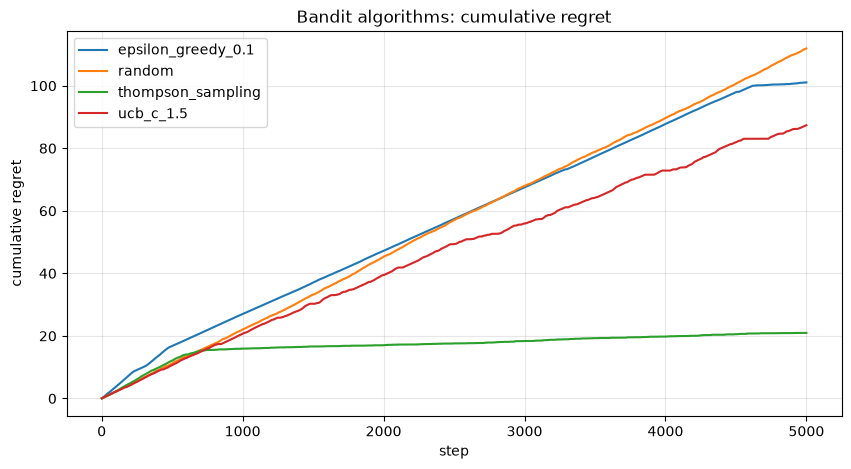

In [16]:
histories = [random_history, eg_history, ucb_history, ts_history]

summary_frames = []
for hist in histories:
    hist = hist.copy()
    hist['regret'] = cumulative_regret(hist['arm'].to_numpy())
    summary_frames.append(hist)

all_results = pd.concat(summary_frames, ignore_index=True)

plt.figure(figsize=(10, 5))
for policy, df in all_results.groupby('policy'):
    plt.plot(df['t'], df['regret'], label=policy)
plt.xlabel('step')
plt.ylabel('cumulative regret')
plt.title('Bandit algorithms: cumulative regret')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [17]:
final_summary = (
    all_results
    .groupby('policy')
    .agg(
        total_reward=('reward', 'sum'),
        final_regret=('regret', 'last'),
        best_arm_share=('arm', lambda x: np.mean(x == best_arm)),
    )
    .sort_values('final_regret')
)

final_summary

,total_reward,final_regret,best_arm_share
policy,,,
thompson_sampling,319,20.96,0.8554
ucb_c_1.5,311,87.36,0.4048
epsilon_greedy_0.1,211,101.06,0.1002
random,230,111.92,0.2562


## 10. Когда бандиты уместны, а когда лучше A/B-тест

Бандиты полезны, когда:

- решения нужно принимать онлайн;
- плохие варианты дорого показывать долго;
- цель — максимизировать награду уже во время эксперимента;
- есть короткий цикл обратной связи.

Классический A/B-тест часто лучше, когда:

- нужна чистая causal-интерпретация;
- есть долгосрочные эффекты;
- метрика приходит с большой задержкой;
- нужно заранее зафиксированное сравнение вариантов.

Бандиты — это не замена A/B-тестам. Это другой инструмент для другой постановки задачи.